# Pneumonia Visualization + Self-Adaptive Training
Includes visualization and self-adaptive transfer learning.


In [1]:
!pip install kagglehub tensorflow matplotlib scikit-learn

In [2]:
import kagglehub, os
base_path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')
train_path = os.path.join(base_path, 'chest_xray', 'train')
test_path = os.path.join(base_path, 'chest_xray', 'test')
print(train_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia/chest_xray/train


In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

## Data + Visualization

In [4]:
datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)

train_data = datagen.flow_from_directory(train_path, target_size=(224,224), batch_size=16, class_mode='binary', subset='training')
val_data = datagen.flow_from_directory(train_path, target_size=(224,224), batch_size=16, class_mode='binary', subset='validation')

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.


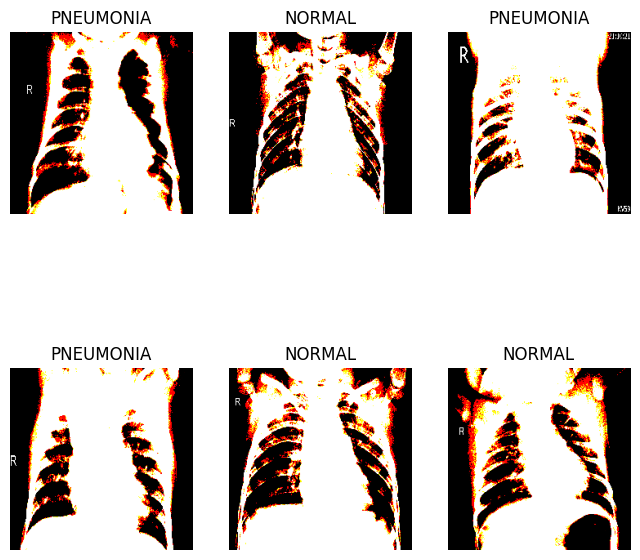

In [5]:
images, labels = next(train_data)
plt.figure(figsize=(8,8))
for i in range(6):
 plt.subplot(2,3,i+1)
 plt.imshow(images[i])
 plt.title('PNEUMONIA' if labels[i]==1 else 'NORMAL')
 plt.axis('off')
plt.show()

## Self-Adaptive Transfer Learning

In [6]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))

for layer in base_model.layers:
 layer.trainable = False

model = models.Sequential([
 base_model,
 layers.GlobalAveragePooling2D(),
 layers.Dense(128, activation='relu'),
 layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(train_data, validation_data=val_data, epochs=3)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
261/261 ━━━━━━━━━━━━━━━━━━━━ 113s 382ms/step - accuracy: 0.9490 - loss: 0.1429 - val_accuracy: 0.9501 - val_loss: 0.1112
Epoch 2/3
261/261 ━━━━━━━━━━━━━━━━━━━━ 52s 198ms/step - accuracy: 0.9686 - loss: 0.0809 - val_accuracy: 0.9885 - val_loss: 0.0427
Epoch 3/3
261/261 ━━━━━━━━━━━━━━━━━━━━ 51s 196ms/step - accuracy: 0.9799 - loss: 0.0561 - val_accuracy: 0.9732 - val_loss: 0.0702


## Adaptive Fine-Tuning

In [ ]:
for layer in base_model.layers[-20:]:
 layer.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=['accuracy'])

callbacks = [
 tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True),
 tf.keras.callbacks.ReduceLROnPlateau(patience=1)
]

model.fit(train_data, validation_data=val_data, epochs=5, callbacks=callbacks)

Epoch 1/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 80s 248ms/step - accuracy: 0.9851 - loss: 0.0414 - val_accuracy: 0.9875 - val_loss: 0.0356 - learning_rate: 1.0000e-05
Epoch 2/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 51s 197ms/step - accuracy: 0.9983 - loss: 0.0126 - val_accuracy: 0.9904 - val_loss: 0.0326 - learning_rate: 1.0000e-05
Epoch 3/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 52s 199ms/step - accuracy: 0.9998 - loss: 0.0056 - val_accuracy: 0.9885 - val_loss: 0.0327 - learning_rate: 1.0000e-05
Epoch 4/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 53s 202ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 0.9885 - val_loss: 0.0319 - learning_rate: 1.0000e-06
Epoch 5/5
114/261 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step - accuracy: 1.0000 - loss: 0.0027